# 2.1 Diseño del tensor de entrada

Para cada máquina *m* y hora *t*, el modelo recibe una **ventana de *L* horas** (*t* − *L* + 1, …, *t*) con 13 canales dinámicos y dos entradas estáticas. Se exploran *L* ∈ {24, 72, 168} (notebook 03).

**Canales dinámicos** (`src/windows.py`, `CHANNELS`):

| Grupo | Canales | Transformación |
|---|---|---|
| Sensores | `volt`, `rotate`, `pressure`, `vibration` | z-score global (estadísticas de train) |
| Errores | `error1_ind` … `error5_ind` | indicador 0/1 por hora; sin transformar |
| Mantenimiento | `log_h_since_comp1` … `comp4` | log(1 + horas desde el último reemplazo con fecha ≤ *t*), z-score global |

**Entradas estáticas:** índice del modelo de máquina (embedding de dimensión 4) y antigüedad (z-score).

**Causalidad.** La ventana solo contiene valores con marca de tiempo ≤ *t*; las horas anteriores al inicio de la serie (primera semana de enero) se rellenan con ceros, que tras la normalización equivalen a la media. Las ventanas no se materializan: se extraen por indexación sobre un tensor (100 máquinas × 8 761 h × 13 canales), lo que permite entrenar con las 580 200 horas de train sin copiar datos.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plots import set_style, savefig

set_style()
pd.set_option("display.precision", 3)
FIG = ROOT / "entrega2" / "figures"
RES = ROOT / "entrega2" / "results"
RUNS = RES / "runs"


def load_run(name):
    m = json.loads((RUNS / name / "metrics.json").read_text())
    m["history"] = pd.read_csv(RUNS / name / "history.csv")
    return m

import torch
from src.data import SPLITS, MODELS, SENSORS, load_machines
from src.windows import CHANNELS, L_VALUES, Normalizer, SplitIndex, WindowTensor, build_channels

X, machines, t0 = build_channels()
norm = Normalizer().fit(X, t0, machines)
times = t0 + pd.to_timedelta(np.arange(X.shape[1]), unit="h")
print("tensor crudo", X.shape, "| rejilla", times.min(), "→", times.max())


tensor crudo (100, 8761, 13) | rejilla 2015-01-01 06:00:00 → 2016-01-01 06:00:00


## 1. Normalización: ¿global, por modelo o por máquina?

Las estadísticas se calculan **solo con las horas de entrenamiento** (ene–ago 2015). La comparación por modelo muestra que los cuatro modelos tienen la misma media y desviación en los cuatro sensores (ya visto en la Figura 1 de la Entrega 1), así que normalizar por modelo no cambiaría nada. Normalizar **por máquina** sería contraproducente: la media de cada máquina incluiría sus propios periodos pre-falla (escalón de 48 h), y en producción habría que recalcularla con datos que aún no existen. Se elige la normalización **global**.

In [2]:
lo, hi = SPLITS["train"]
train_mask = (times >= lo) & (times <= hi)
rows = []
for mi, model in enumerate(MODELS):
    sub = X[(machines["model_idx"] == mi).to_numpy()][:, train_mask, :4].reshape(-1, 4)
    for j, s in enumerate(SENSORS):
        rows.append({"modelo": model, "sensor": s, "media": sub[:, j].mean(), "std": sub[:, j].std()})
by_model = pd.DataFrame(rows).pivot(index="sensor", columns="modelo", values=["media", "std"])
by_model.to_csv(RES / "sensors_by_model_train.csv")
by_model

media                                std                        
modelo      model1   model2   model3   model4  model1  model2  model3  model4
sensor                                                                       
pressure   101.212  101.138  100.633  100.630  11.477  11.334  10.814  10.809
rotate     446.691  446.436  446.515  446.670  52.828  52.721  52.675  52.484
vibration   40.440   40.383   40.421   40.342   5.403   5.359   5.363   5.352
volt       170.754  170.909  170.855  170.728  15.558  15.644  15.481  15.447

In [3]:
stats = pd.DataFrame({"canal": CHANNELS, "media (train)": norm.mean, "std (train)": norm.std})
stats.to_csv(RES / "normalizer_stats.csv", index=False)
stats

,canal,media (train),std (train)
0,volt,170.806,15.509
1,rotate,446.572,52.640
2,pressure,100.810,11.012
3,vibration,40.392,5.365
4,error1_ind,0.000,1.000
5,error2_ind,0.000,1.000
6,error3_ind,0.000,1.000
7,error4_ind,0.000,1.000
8,error5_ind,0.000,1.000
9,log_h_since_comp1,6.550,1.343


## 2. Verificación de causalidad y de la partición

Comprobaciones sobre una muestra aleatoria de horas de validación: la ventana devuelta coincide con los canales de las horas *t* − *L* + 1, …, *t* (nada posterior a *t*), y las estadísticas del normalizador no usan horas de validación.

In [4]:
wt = WindowTensor(norm.transform(X), machines, norm, "cpu")
splits = {s: SplitIndex(s, machines, t0) for s in ("train", "val")}
Xn = norm.transform(X)
rng = np.random.default_rng(14)
sel = rng.choice(len(splits["val"]), 300, replace=False)
va = splits["val"]
for L in L_VALUES:
    x, _, _ = wt.batch(torch.from_numpy(va.m[sel]), torch.from_numpy(va.t[sel]), L)
    ref = np.stack([Xn[m, t - L + 1:t + 1] for m, t in zip(va.m[sel], va.t[sel])])
    assert np.allclose(x.numpy(), ref), L
assert np.allclose(norm.mean[:4], X[:, train_mask, :4].reshape(-1, 4).mean(axis=0))
assert va.datetime.min() >= np.datetime64(SPLITS["val"][0]) and va.datetime.max() <= np.datetime64(SPLITS["val"][1])
print("ventanas causales y normalizador solo con train: OK")
pd.DataFrame({s: {"horas": len(sp), "positivas": sp.y_bin.mean(), "desde": sp.datetime.min(), "hasta": sp.datetime.max()}
              for s, sp in splits.items()}).T

ventanas causales y normalizador solo con train: OK


,horas,positivas,desde,hasta
train,580200,0.02,2015-01-01T06:00:00.000000000,2015-08-30T23:00:00.000000000
val,144000,0.018,2015-09-01T00:00:00.000000000,2015-10-30T23:00:00.000000000


## 3. Diagrama del tensor de entrada

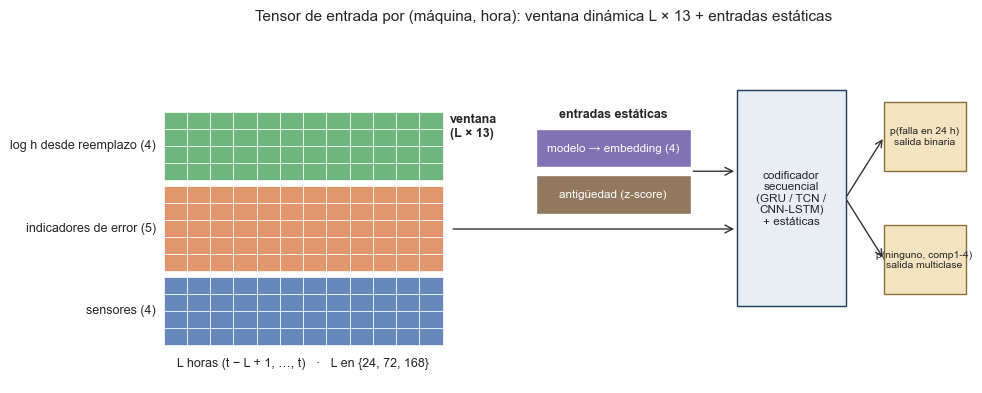

In [5]:
from matplotlib.patches import FancyArrowPatch, Rectangle

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 4.6); ax.axis("off")
groups = [("sensores (4)", 4, "#4c72b0"), ("indicadores de error (5)", 5, "#dd8452"), ("log h desde reemplazo (4)", 4, "#55a868")]
y, cell = 0.5, 0.22
L = 12  # columnas dibujadas (representan L horas)
for label, n, color in groups:
    for i in range(n):
        for j in range(L):
            ax.add_patch(Rectangle((0.6 + j * 0.3, y + i * cell), 0.3, cell, fc=color, ec="white", lw=0.6, alpha=0.85))
    ax.text(0.5, y + n * cell / 2, label, ha="right", va="center", fontsize=9)
    y += n * cell + 0.08
ax.text(0.6 + L * 0.3 / 2, 0.22, "L horas (t − L + 1, …, t)   ·   L en {24, 72, 168}", ha="center", fontsize=9)
ax.text(0.6 + L * 0.3 + 0.1, y - 0.1, "ventana\n(L × 13)", va="top", fontsize=9, fontweight="bold")
# estáticas
ax.add_patch(Rectangle((5.4, 2.8), 2.0, 0.5, fc="#8172b3", ec="white"))
ax.text(6.4, 3.05, "modelo → embedding (4)", ha="center", va="center", fontsize=8.5, color="white")
ax.add_patch(Rectangle((5.4, 2.2), 2.0, 0.5, fc="#937860", ec="white"))
ax.text(6.4, 2.45, "antigüedad (z-score)", ha="center", va="center", fontsize=8.5, color="white")
ax.text(6.4, 3.45, "entradas estáticas", ha="center", fontsize=9, fontweight="bold")
# modelo y salidas
ax.add_patch(Rectangle((8.0, 1.0), 1.4, 2.8, fc="#e8eef4", ec="#1f3b57"))
ax.text(8.7, 2.4, "codificador\nsecuencial\n(GRU / TCN /\nCNN-LSTM)\n+ estáticas", ha="center", va="center", fontsize=8.5)
for yy, txt in [(3.2, "p(falla en 24 h)\nsalida binaria"), (1.6, "p(ninguno, comp1-4)\nsalida multiclase")]:
    ax.add_patch(Rectangle((9.9, yy - 0.45), 1.05, 0.9, fc="#f4e3c1", ec="#8a6d3b"))
    ax.text(10.42, yy, txt, ha="center", va="center", fontsize=7.5)
    ax.add_patch(FancyArrowPatch((9.4, 2.4), (9.9, yy), arrowstyle="->", mutation_scale=12, color="#333"))
ax.add_patch(FancyArrowPatch((4.3, 2.0), (8.0, 2.0), arrowstyle="->", mutation_scale=14, color="#333"))
ax.add_patch(FancyArrowPatch((7.4, 2.75), (8.0, 2.75), arrowstyle="->", mutation_scale=14, color="#333"))
ax.set_title("Tensor de entrada por (máquina, hora): ventana dinámica L × 13 + entradas estáticas", fontsize=11)
savefig(fig, "01_tensor_diagram", FIG)